# 03 — Multi-class Classification

## Mục tiêu

Xây dựng mô hình phân loại để dự báo mức độ mua hàng của khách hàng (`Purchase_Level`) gồm ba lớp:

- **Low:** `Total_Purchases <= 10`
- **Medium:** `10 < Total_Purchases <= 15`
- **High:** `Total_Purchases > 15`

Các mô hình dự kiến được thử nghiệm:

1. Logistic Regression
2. Random Forest
3. XGBoost
4. Neural Network

`Total_Purchases` không được sử dụng làm biến đầu vào vì `Purchase_Level`
được xây dựng trực tiếp từ thuộc tính này.

`Lifetime_Value` sẽ được đánh giá riêng thông qua ablation experiment
để xem ảnh hưởng của biến này đến kết quả mô hình.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ecommerce_customer_behavior_with_target.csv"
)

print("Dataset path:")
print(DATA_PATH)


# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("\nDataset shape:")
print(df.shape)

display(df.head())

Dataset path:
data\processed\ecommerce_customer_behavior_with_target.csv

Dataset shape:
(49960, 26)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Purchase_Level
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1,Low
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,7.0,3.0,27.6,23.3,3.0,1067.47,3028.0,0,Q4,High
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,4.0,1.0,27.6,8.8,2.0,1289.75,2317.0,0,Q4,Low
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1,Medium
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,...,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4,High


In [2]:
# ============================================================
# TARGET
# ============================================================

TARGET = "Purchase_Level"


# ============================================================
# DIRECT LEAKAGE FEATURES
# ============================================================

LEAKAGE_FEATURES = [
    "Total_Purchases",
]


# ============================================================
# X / y
# ============================================================

X = df.drop(
    columns=[
        TARGET,
        *LEAKAGE_FEATURES,
    ]
)

y = df[TARGET].copy()


print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nCác feature bị loại vì leakage:")
print(LEAKAGE_FEATURES)

print("\nSố feature đầu vào:")
print(X.shape[1])

print("\nDanh sách feature:")
for feature in X.columns:
    print("-", feature)

X shape: (49960, 24)
y shape: (49960,)

Các feature bị loại vì leakage:
['Total_Purchases']

Số feature đầu vào:
24

Danh sách feature:
- Age
- Gender
- Country
- City
- Membership_Years
- Login_Frequency
- Session_Duration_Avg
- Pages_Per_Session
- Cart_Abandonment_Rate
- Wishlist_Items
- Average_Order_Value
- Days_Since_Last_Purchase
- Discount_Usage_Rate
- Returns_Rate
- Email_Open_Rate
- Customer_Service_Calls
- Product_Reviews_Written
- Social_Media_Engagement_Score
- Mobile_App_Usage
- Payment_Method_Diversity
- Lifetime_Value
- Credit_Balance
- Churned
- Signup_Quarter


In [3]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)


print("Train shape:")
print(X_train.shape)

print("\nTest shape:")
print(X_test.shape)


# ============================================================
# KIỂM TRA PHÂN BỐ TARGET
# ============================================================

train_distribution = (
    y_train
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

test_distribution = (
    y_test
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

distribution = pd.DataFrame({
    "Train (%)": train_distribution,
    "Test (%)": test_distribution,
})

distribution = distribution.reindex([
    "Low",
    "Medium",
    "High",
])

print("\nPhân bố Purchase_Level:")
display(distribution)

Train shape:
(39968, 24)

Test shape:
(9992, 24)

Phân bố Purchase_Level:


,Train (%),Test (%)
Purchase_Level,,
Low,37.94,37.94
Medium,30.28,30.28
High,31.78,31.78


## 2. Preprocessing

Dữ liệu đầu vào gồm cả biến số và biến phân loại.

- Biến số được chuẩn hóa bằng `StandardScaler`.
- Biến phân loại được mã hóa bằng `OneHotEncoder`.
- Quá trình preprocessing được đặt trong `ColumnTransformer`.
- Preprocessor chỉ được `fit` trên tập training thông qua Pipeline để tránh data leakage.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# ============================================================
# XÁC ĐỊNH KIỂU FEATURE
# ============================================================

numeric_features = (
    X_train
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)


print("Numeric features:")
print(f"Số lượng: {len(numeric_features)}")

for feature in numeric_features:
    print("-", feature)


print("\nCategorical features:")
print(f"Số lượng: {len(categorical_features)}")

for feature in categorical_features:
    print("-", feature)


print(
    "\nTổng:",
    len(numeric_features) + len(categorical_features)
)

Numeric features:
Số lượng: 20
- Age
- Membership_Years
- Login_Frequency
- Session_Duration_Avg
- Pages_Per_Session
- Cart_Abandonment_Rate
- Wishlist_Items
- Average_Order_Value
- Days_Since_Last_Purchase
- Discount_Usage_Rate
- Returns_Rate
- Email_Open_Rate
- Customer_Service_Calls
- Product_Reviews_Written
- Social_Media_Engagement_Score
- Mobile_App_Usage
- Payment_Method_Diversity
- Lifetime_Value
- Credit_Balance
- Churned

Categorical features:
Số lượng: 4
- Gender
- Country
- City
- Signup_Quarter

Tổng: 24


In [5]:
# ============================================================
# PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features,
        ),
    ],
    remainder="drop",
)


print("Preprocessor đã được tạo.")
print("Chưa fit dữ liệu.")

Preprocessor đã được tạo.
Chưa fit dữ liệu.


## 3. Logistic Regression Baseline

Logistic Regression được sử dụng làm mô hình baseline cho bài toán phân loại đa lớp.

Mô hình được kết hợp với bước tiền xử lý trong cùng một `Pipeline`.
Điều này đảm bảo các tham số của `StandardScaler` và `OneHotEncoder`
chỉ được học từ tập training.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


# ============================================================
# LOGISTIC REGRESSION PIPELINE
# ============================================================

logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor,
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42,
            ),
        ),
    ]
)


print(logistic_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Age', 'Membership_Years',
                                                   'Login_Frequency',
                                                   'Session_Duration_Avg',
                                                   'Pages_Per_Session',
                                                   'Cart_Abandonment_Rate',
                                                   'Wishlist_Items',
                                                   'Average_Order_Value',
                                                   'Days_Since_Last_Purchase',
                                                   'Discount_Usage_Rate',
                                                   'Returns_Rate',
                                                   'Email_Open_Rate',
                                                   'Customer_Service_Calls',
       

In [7]:
import time


# ============================================================
# TRAIN LOGISTIC REGRESSION
# ============================================================

start_time = time.perf_counter()

logistic_pipeline.fit(
    X_train,
    y_train,
)

training_time = (
    time.perf_counter() - start_time
)


print("Logistic Regression training completed.")

print(
    f"Training time: "
    f"{training_time:.2f} seconds"
)

Logistic Regression training completed.
Training time: 0.51 seconds


In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)


# ============================================================
# PREDICTION
# ============================================================

y_pred_logistic = logistic_pipeline.predict(
    X_test
)


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred_logistic,
)

precision_macro = precision_score(
    y_test,
    y_pred_logistic,
    average="macro",
)

recall_macro = recall_score(
    y_test,
    y_pred_logistic,
    average="macro",
)

f1_macro = f1_score(
    y_test,
    y_pred_logistic,
    average="macro",
)


print("=" * 60)
print("LOGISTIC REGRESSION — BASELINE")
print("=" * 60)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {precision_macro:.4f}")
print(f"Macro Recall    : {recall_macro:.4f}")
print(f"Macro F1-score  : {f1_macro:.4f}")


print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        labels=[
            "Low",
            "Medium",
            "High",
        ],
        digits=4,
    )
)

LOGISTIC REGRESSION — BASELINE
Accuracy        : 0.8059
Macro Precision : 0.8024
Macro Recall    : 0.7997
Macro F1-score  : 0.8008

Classification Report:



              precision    recall  f1-score   support

         Low     0.8452    0.8739    0.8593      3791
      Medium     0.6824    0.6874    0.6849      3026
        High     0.8796    0.8378    0.8582      3175

    accuracy                         0.8059      9992
   macro avg     0.8024    0.7997    0.8008      9992
weighted avg     0.8068    0.8059    0.8061      9992



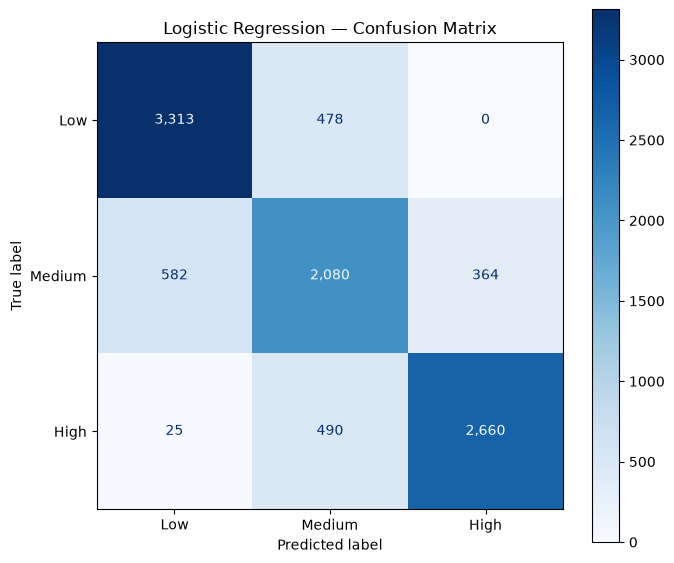

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay


class_order = [
    "Low",
    "Medium",
    "High",
]

cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=class_order,
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order,
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
)

plt.title(
    "Logistic Regression — Confusion Matrix"
)

plt.tight_layout()
plt.show()

## 4. Lifetime Value Ablation Experiment

`Lifetime_Value` có tương quan tương đối mạnh với `Purchase_Level`.
Tuy nhiên, tương quan cao không đồng nghĩa với data leakage.

Để đánh giá mức độ ảnh hưởng của thuộc tính này, Logistic Regression
được huấn luyện lại trong hai trường hợp:

1. Có `Lifetime_Value`.
2. Không có `Lifetime_Value`.

Các mô hình sử dụng cùng train/test split để đảm bảo kết quả có thể so sánh trực tiếp.

In [10]:
# ============================================================
# TẠO DATASET KHÔNG CÓ LIFETIME_VALUE
# ============================================================

X_train_no_ltv = X_train.drop(
    columns=["Lifetime_Value"]
)

X_test_no_ltv = X_test.drop(
    columns=["Lifetime_Value"]
)


numeric_features_no_ltv = (
    X_train_no_ltv
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_features_no_ltv = (
    X_train_no_ltv
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)


print("Original features :", X_train.shape[1])
print("Without LTV       :", X_train_no_ltv.shape[1])

print(
    "Lifetime_Value exists:",
    "Lifetime_Value" in X_train_no_ltv.columns
)

Original features : 24
Without LTV       : 23
Lifetime_Value exists: False


In [11]:
# ============================================================
# PREPROCESSOR WITHOUT LIFETIME_VALUE
# ============================================================

preprocessor_no_ltv = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features_no_ltv,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features_no_ltv,
        ),
    ],
    remainder="drop",
)


# ============================================================
# LOGISTIC REGRESSION WITHOUT LIFETIME_VALUE
# ============================================================

logistic_no_ltv = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_no_ltv,
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42,
            ),
        ),
    ]
)


logistic_no_ltv.fit(
    X_train_no_ltv,
    y_train,
)

y_pred_no_ltv = logistic_no_ltv.predict(
    X_test_no_ltv
)

print("Training completed.")

Training completed.


In [12]:
# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),
    }


# ============================================================
# CALCULATE
# ============================================================

metrics_with_ltv = calculate_metrics(
    y_test,
    y_pred_logistic,
)

metrics_without_ltv = calculate_metrics(
    y_test,
    y_pred_no_ltv,
)


comparison = pd.DataFrame(
    [
        metrics_with_ltv,
        metrics_without_ltv,
    ],
    index=[
        "With Lifetime_Value",
        "Without Lifetime_Value",
    ],
)


display(
    comparison.round(4)
)


# ============================================================
# DIFFERENCE
# ============================================================

difference = (
    comparison.loc["With Lifetime_Value"]
    - comparison.loc["Without Lifetime_Value"]
)

print(
    "\nDifference "
    "(With LTV - Without LTV):"
)

display(
    difference
    .to_frame("Difference")
    .round(4)
)


print(
    classification_report(
        y_test,
        y_pred_no_ltv,
        labels=[
            "Low",
            "Medium",
            "High",
        ],
        digits=4,
    )
)

,Accuracy,Macro Precision,Macro Recall,Macro F1
With Lifetime_Value,0.8059,0.8024,0.7997,0.8008
Without Lifetime_Value,0.7190,0.7096,0.7090,0.7086



Difference (With LTV - Without LTV):


,Difference
Accuracy,0.0870
Macro Precision,0.0928
Macro Recall,0.0907
Macro F1,0.0922


              precision    recall  f1-score   support

         Low     0.7656    0.8277    0.7954      3791
      Medium     0.5679    0.5291    0.5478      3026
        High     0.7954    0.7701    0.7825      3175

    accuracy                         0.7190      9992
   macro avg     0.7096    0.7090    0.7086      9992
weighted avg     0.7152    0.7190    0.7163      9992



## Random Forest Baseline

Huấn luyện mô hình Random Forest trên cùng tập train/test và cùng tập đặc trưng
đã sử dụng cho Logistic Regression để so sánh hiệu quả giữa mô hình tuyến tính
và mô hình phi tuyến.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

import time


rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])


start_time = time.time()

rf_pipeline.fit(X_train, y_train)

rf_training_time = time.time() - start_time

y_pred_rf = rf_pipeline.predict(X_test)


rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average="macro",
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average="macro",
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro",
)


CLASS_ORDER = ["Low", "Medium", "High"]

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=CLASS_ORDER,
)


print("RANDOM FOREST BASELINE")
print("=" * 50)
print(f"Training time    : {rf_training_time:.2f} seconds")
print(f"Accuracy         : {rf_accuracy:.4f}")
print(f"Macro Precision  : {rf_precision:.4f}")
print(f"Macro Recall     : {rf_recall:.4f}")
print(f"Macro F1-score   : {rf_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(cm_rf)

RANDOM FOREST BASELINE
Training time    : 3.72 seconds
Accuracy         : 0.8007
Macro Precision  : 0.7981
Macro Recall     : 0.7938
Macro F1-score   : 0.7953

Classification Report:
              precision    recall  f1-score   support

        High       0.87      0.80      0.83      3175
         Low       0.86      0.88      0.87      3791
      Medium       0.67      0.70      0.68      3026

    accuracy                           0.80      9992
   macro avg       0.80      0.79      0.80      9992
weighted avg       0.80      0.80      0.80      9992


Confusion Matrix:
[[3350  441    0]
 [ 515 2121  390]
 [  25  620 2530]]


## Random Forest Feature Importance

Phân tích mức độ đóng góp của các đặc trưng trong mô hình Random Forest
nhằm xác định những thuộc tính được mô hình sử dụng nhiều trong quá trình
dự báo Purchase_Level.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt


# Lấy tên feature sau preprocessing
feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Lấy feature importance từ Random Forest
importances = (
    rf_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
}).sort_values(
    by="Importance",
    ascending=False,
)

print("TOP 20 RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 60)
print(rf_feature_importance.head(20).to_string(index=False))

TOP 20 RANDOM FOREST FEATURE IMPORTANCE
                               Feature  Importance
               numeric__Lifetime_Value    0.142354
         numeric__Session_Duration_Avg    0.084752
            numeric__Pages_Per_Session    0.074740
             numeric__Mobile_App_Usage    0.066617
          numeric__Average_Order_Value    0.062003
        numeric__Cart_Abandonment_Rate    0.060182
              numeric__Login_Frequency    0.051151
              numeric__Email_Open_Rate    0.046031
numeric__Social_Media_Engagement_Score    0.039000
               numeric__Wishlist_Items    0.037518
               numeric__Credit_Balance    0.034381
        categorical__Signup_Quarter_Q4    0.034099
      numeric__Product_Reviews_Written    0.024773
          numeric__Discount_Usage_Rate    0.024506
                 numeric__Returns_Rate    0.023844
             numeric__Membership_Years    0.022610
     numeric__Days_Since_Last_Purchase    0.022391
                          numeric__Age    

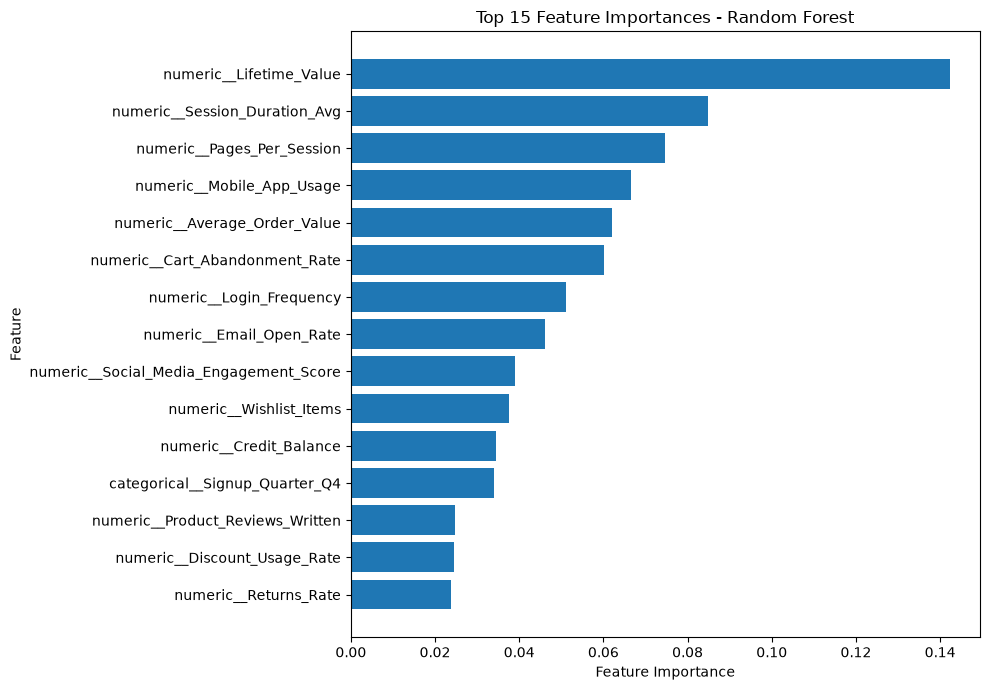

In [15]:
top_n = 15

plot_data = rf_feature_importance.head(top_n).sort_values(
    "Importance",
    ascending=True,
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance"],
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

## Random Forest — Lifetime Value Ablation

Thực hiện thí nghiệm loại bỏ `Lifetime_Value` khỏi tập đặc trưng để đánh giá
mức độ ảnh hưởng của biến này đến hiệu năng của Random Forest.

Thí nghiệm sử dụng cùng train/test split và cùng cấu hình Random Forest baseline
để đảm bảo khả năng so sánh.

In [16]:
# ============================================================
# PREPROCESSOR WITHOUT LIFETIME_VALUE
# ============================================================

rf_preprocessor_no_ltv = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features_no_ltv,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features_no_ltv,
        ),
    ],
    remainder="drop",
)


# ============================================================
# RANDOM FOREST WITHOUT LIFETIME_VALUE
# ============================================================

rf_pipeline_no_ltv = Pipeline([
    ("preprocessor", rf_preprocessor_no_ltv),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])


start_time = time.time()

rf_pipeline_no_ltv.fit(
    X_train_no_ltv,
    y_train,
)

rf_no_ltv_training_time = time.time() - start_time

y_pred_rf_no_ltv = rf_pipeline_no_ltv.predict(
    X_test_no_ltv
)

print("Random Forest without Lifetime_Value training completed.")
print(f"Training time: {rf_no_ltv_training_time:.2f} seconds")

Random Forest without Lifetime_Value training completed.
Training time: 4.99 seconds


In [17]:
# ============================================================
# METRICS WITHOUT LIFETIME_VALUE
# ============================================================

rf_no_ltv_accuracy = accuracy_score(
    y_test,
    y_pred_rf_no_ltv,
)

rf_no_ltv_precision = precision_score(
    y_test,
    y_pred_rf_no_ltv,
    average="macro",
)

rf_no_ltv_recall = recall_score(
    y_test,
    y_pred_rf_no_ltv,
    average="macro",
)

rf_no_ltv_f1 = f1_score(
    y_test,
    y_pred_rf_no_ltv,
    average="macro",
)

cm_rf_no_ltv = confusion_matrix(
    y_test,
    y_pred_rf_no_ltv,
    labels=CLASS_ORDER,
)


print("RANDOM FOREST WITHOUT LIFETIME_VALUE")
print("=" * 50)
print(f"Training time    : {rf_no_ltv_training_time:.2f} seconds")
print(f"Accuracy         : {rf_no_ltv_accuracy:.4f}")
print(f"Macro Precision  : {rf_no_ltv_precision:.4f}")
print(f"Macro Recall     : {rf_no_ltv_recall:.4f}")
print(f"Macro F1-score   : {rf_no_ltv_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf_no_ltv,
        labels=CLASS_ORDER,
        digits=4,
    )
)

print("Confusion Matrix [Low, Medium, High]:")
print(cm_rf_no_ltv)

RANDOM FOREST WITHOUT LIFETIME_VALUE
Training time    : 4.99 seconds
Accuracy         : 0.7210
Macro Precision  : 0.7168
Macro Recall     : 0.7097
Macro F1-score   : 0.7110

Classification Report:
              precision    recall  f1-score   support

         Low     0.7483    0.8523    0.7969      3791
      Medium     0.5769    0.5443    0.5601      3026
        High     0.8251    0.7326    0.7761      3175

    accuracy                         0.7210      9992
   macro avg     0.7168    0.7097    0.7110      9992
weighted avg     0.7208    0.7210    0.7186      9992

Confusion Matrix [Low, Medium, High]:
[[3231  552    8]
 [ 894 1647  485]
 [ 193  656 2326]]


In [18]:
# ============================================================
# RANDOM FOREST ABLATION COMPARISON
# ============================================================

rf_metrics_with_ltv = {
    "Accuracy": rf_accuracy,
    "Macro Precision": rf_precision,
    "Macro Recall": rf_recall,
    "Macro F1": rf_f1,
}

rf_metrics_without_ltv = {
    "Accuracy": rf_no_ltv_accuracy,
    "Macro Precision": rf_no_ltv_precision,
    "Macro Recall": rf_no_ltv_recall,
    "Macro F1": rf_no_ltv_f1,
}

rf_ltv_comparison = pd.DataFrame(
    [
        rf_metrics_with_ltv,
        rf_metrics_without_ltv,
    ],
    index=[
        "Random Forest with Lifetime_Value",
        "Random Forest without Lifetime_Value",
    ],
)

display(rf_ltv_comparison.round(4))

rf_ltv_difference = (
    rf_ltv_comparison.loc["Random Forest with Lifetime_Value"]
    - rf_ltv_comparison.loc["Random Forest without Lifetime_Value"]
)

print("\nDifference (With LTV - Without LTV):")
display(
    rf_ltv_difference
    .to_frame("Difference")
    .round(4)
)

,Accuracy,Macro Precision,Macro Recall,Macro F1
Random Forest with Lifetime_Value,0.8007,0.7981,0.7938,0.7953
Random Forest without Lifetime_Value,0.7210,0.7168,0.7097,0.7110



Difference (With LTV - Without LTV):


,Difference
Accuracy,0.0798
Macro Precision,0.0813
Macro Recall,0.0841
Macro F1,0.0842


## XGBoost Baseline

Huấn luyện XGBoost trên cùng train/test split và cùng 24 đặc trưng của các baseline trước.
`Total_Purchases` tiếp tục bị loại để tránh direct target leakage, trong khi
`Lifetime_Value` được giữ lại để bảo đảm so sánh công bằng.

Target được mã hóa theo thứ tự: `Low=0`, `Medium=1`, `High=2`.

In [19]:
from sklearn.base import clone
from xgboost import XGBClassifier


# ============================================================
# TARGET ENCODING
# ============================================================

TARGET_ENCODING = {
    "Low": 0,
    "Medium": 1,
    "High": 2,
}

ENCODED_CLASS_ORDER = [0, 1, 2]

y_train_xgb = y_train.map(TARGET_ENCODING).astype(int)
y_test_xgb = y_test.map(TARGET_ENCODING).astype(int)


# ============================================================
# XGBOOST BASELINE PIPELINE
# ============================================================

xgb_classifier = XGBClassifier(
    n_estimators=100,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
)

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", xgb_classifier),
])


start_time = time.time()

xgb_pipeline.fit(
    X_train,
    y_train_xgb,
)

xgb_training_time = time.time() - start_time

y_pred_xgb = xgb_pipeline.predict(X_test)

print("XGBoost training completed.")
print(f"Input features : {X_train.shape[1]}")
print(f"Training time : {xgb_training_time:.2f} seconds")
print("Target encoding:", TARGET_ENCODING)
print("\nXGBClassifier configuration:")
print(xgb_classifier)

XGBoost training completed.
Input features : 24
Training time : 3.75 seconds
Target encoding: {'Low': 0, 'Medium': 1, 'High': 2}

XGBClassifier configuration:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1, num_class=3, ...)


In [20]:
# ============================================================
# XGBOOST METRICS
# ============================================================

xgb_accuracy = accuracy_score(
    y_test_xgb,
    y_pred_xgb,
)

xgb_precision = precision_score(
    y_test_xgb,
    y_pred_xgb,
    average="macro",
)

xgb_recall = recall_score(
    y_test_xgb,
    y_pred_xgb,
    average="macro",
)

xgb_f1 = f1_score(
    y_test_xgb,
    y_pred_xgb,
    average="macro",
)

cm_xgb = confusion_matrix(
    y_test_xgb,
    y_pred_xgb,
    labels=ENCODED_CLASS_ORDER,
)


print("XGBOOST BASELINE")
print("=" * 60)
print(f"Training time    : {xgb_training_time:.2f} seconds")
print(f"Accuracy         : {xgb_accuracy:.4f}")
print(f"Macro Precision  : {xgb_precision:.4f}")
print(f"Macro Recall     : {xgb_recall:.4f}")
print(f"Macro F1-score   : {xgb_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_xgb,
        y_pred_xgb,
        labels=ENCODED_CLASS_ORDER,
        target_names=CLASS_ORDER,
        digits=4,
    )
)

print("Confusion Matrix [Low, Medium, High]:")
print(cm_xgb)

XGBOOST BASELINE
Training time    : 3.75 seconds
Accuracy         : 0.8693
Macro Precision  : 0.8664
Macro Recall     : 0.8654
Macro F1-score   : 0.8658

Classification Report:
              precision    recall  f1-score   support

         Low     0.9137    0.9127    0.9132      3791
      Medium     0.7761    0.8017    0.7887      3026
        High     0.9094    0.8819    0.8954      3175

    accuracy                         0.8693      9992
   macro avg     0.8664    0.8654    0.8658      9992
weighted avg     0.8706    0.8693    0.8698      9992

Confusion Matrix [Low, Medium, High]:
[[3460  331    0]
 [ 321 2426  279]
 [   6  369 2800]]


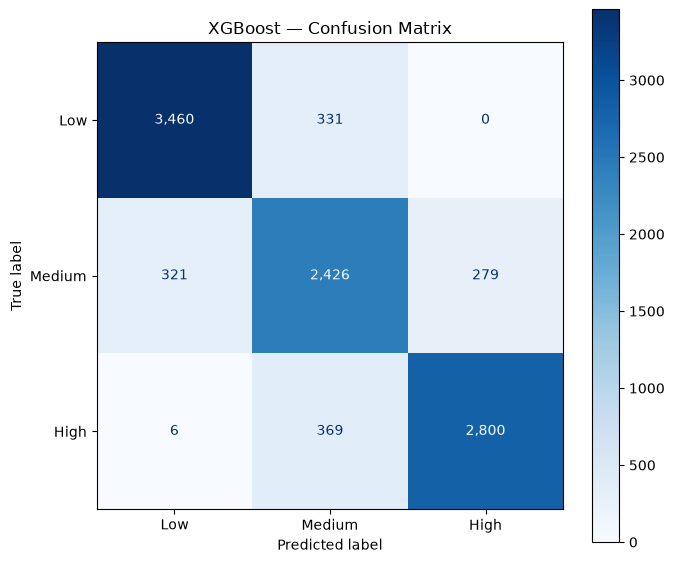

In [21]:
xgb_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=CLASS_ORDER,
)

fig, ax = plt.subplots(figsize=(7, 6))

xgb_cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
)

plt.title("XGBoost — Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# BASELINE MODEL COMPARISON
# ============================================================

baseline_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro,
        "Training Time (s)": training_time,
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Macro Precision": rf_precision,
        "Macro Recall": rf_recall,
        "Macro F1": rf_f1,
        "Training Time (s)": rf_training_time,
    },
    {
        "Model": "XGBoost",
        "Accuracy": xgb_accuracy,
        "Macro Precision": xgb_precision,
        "Macro Recall": xgb_recall,
        "Macro F1": xgb_f1,
        "Training Time (s)": xgb_training_time,
    },
])

display(
    baseline_comparison.set_index("Model").round(4)
)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
Model,,,,,
Logistic Regression,0.8059,0.8024,0.7997,0.8008,0.5090
Random Forest,0.8007,0.7981,0.7938,0.7953,3.7175
XGBoost,0.8693,0.8664,0.8654,0.8658,3.7513


## Neural Network (MLP) Baseline

Huấn luyện `MLPClassifier` trên cùng train/test split, cùng preprocessing và cùng
24 đặc trưng của các baseline trước để bảo đảm khả năng so sánh công bằng.

In [23]:
from sklearn.neural_network import MLPClassifier

import time

In [24]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42,
)

mlp_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", mlp_model),
])

print(mlp_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Age', 'Membership_Years',
                                                   'Login_Frequency',
                                                   'Session_Duration_Avg',
                                                   'Pages_Per_Session',
                                                   'Cart_Abandonment_Rate',
                                                   'Wishlist_Items',
                                                   'Average_Order_Value',
                                                   'Days_Since_Last_Purchase',
                                                   'Discount_Usage_Rate',
                                                   'Returns_Rate',
                                                   'Email_Open_Rate',
                                                   'Customer_Service_Calls',
       

In [25]:
print("=" * 60)
print("NEURAL NETWORK (MLP) BASELINE")
print("=" * 60)

start_time = time.time()

mlp_pipeline.fit(
    X_train,
    y_train,
)

mlp_training_time = time.time() - start_time

print(f"Training time : {mlp_training_time:.2f} seconds")
print(f"Iterations    : {mlp_pipeline.named_steps['classifier'].n_iter_}")

NEURAL NETWORK (MLP) BASELINE


Training time : 10.13 seconds
Iterations    : 25


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


y_pred_mlp = mlp_pipeline.predict(X_test)

mlp_accuracy = accuracy_score(y_test, y_pred_mlp)

mlp_precision = precision_score(
    y_test,
    y_pred_mlp,
    average="macro",
)

mlp_recall = recall_score(
    y_test,
    y_pred_mlp,
    average="macro",
)

mlp_f1 = f1_score(
    y_test,
    y_pred_mlp,
    average="macro",
)

cm_mlp = confusion_matrix(
    y_test,
    y_pred_mlp,
    labels=CLASS_ORDER,
)


print("=" * 60)
print("NEURAL NETWORK RESULTS")
print("=" * 60)
print(f"Accuracy         : {mlp_accuracy:.4f}")
print(f"Macro Precision  : {mlp_precision:.4f}")
print(f"Macro Recall     : {mlp_recall:.4f}")
print(f"Macro F1-score   : {mlp_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_mlp,
        labels=CLASS_ORDER,
        digits=4,
    )
)

print("Confusion Matrix [Low, Medium, High]:")
print(cm_mlp)

NEURAL NETWORK RESULTS
Accuracy         : 0.8675
Macro Precision  : 0.8644
Macro Recall     : 0.8630


Macro F1-score   : 0.8636

Classification Report:
              precision    recall  f1-score   support

         Low     0.9056    0.9182    0.9119      3791
      Medium     0.7761    0.7905    0.7832      3026
        High     0.9116    0.8803    0.8957      3175

    accuracy                         0.8675      9992
   macro avg     0.8644    0.8630    0.8636      9992
weighted avg     0.8683    0.8675    0.8678      9992

Confusion Matrix [Low, Medium, High]:
[[3481  310    0]
 [ 363 2392  271]
 [   0  380 2795]]


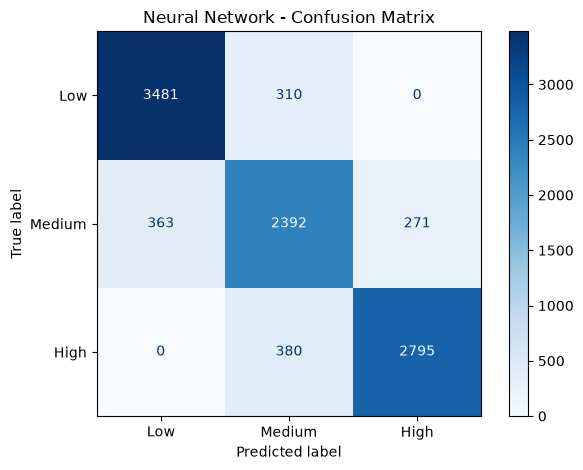

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=CLASS_ORDER,
)

disp.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("Neural Network - Confusion Matrix")
plt.tight_layout()
plt.show()

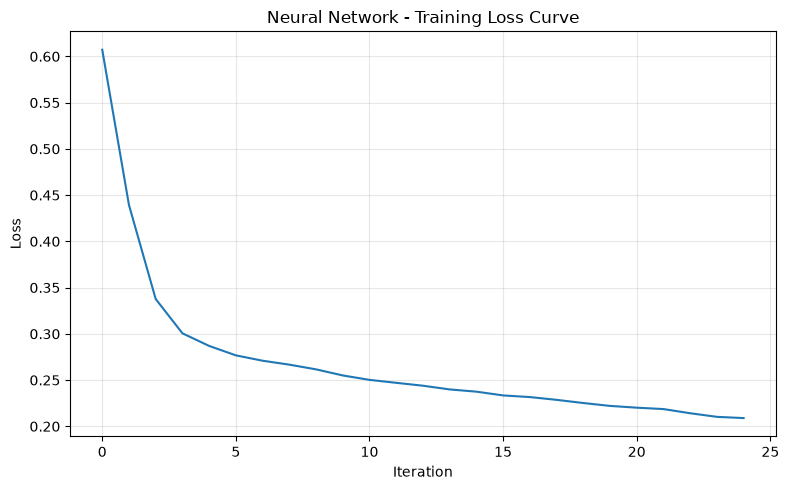

In [28]:
loss_curve = mlp_pipeline.named_steps["classifier"].loss_curve_

plt.figure(figsize=(8, 5))
plt.plot(loss_curve)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Neural Network - Training Loss Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## XGBoost — Lifetime Value Ablation

Loại bỏ duy nhất `Lifetime_Value` và huấn luyện lại XGBoost với cùng train/test
split và cùng cấu hình baseline để đo mức thay đổi hiệu năng.

Thí nghiệm này đánh giá mức độ đóng góp của `Lifetime_Value`; feature importance
hoặc mức giảm hiệu năng tự nó không đủ để kết luận data leakage.

In [29]:
# ============================================================
# XGBOOST - LIFETIME_VALUE ABLATION
# ============================================================

X_train_no_ltv = X_train.drop(columns=["Lifetime_Value"])
X_test_no_ltv = X_test.drop(columns=["Lifetime_Value"])

print("XGBOOST - LIFETIME_VALUE ABLATION")
print("=" * 60)
print(f"Original features : {X_train.shape[1]}")
print(f"Without LTV       : {X_train_no_ltv.shape[1]}")
print(
    "Lifetime_Value exists:",
    "Lifetime_Value" in X_train_no_ltv.columns,
)

XGBOOST - LIFETIME_VALUE ABLATION
Original features : 24
Without LTV       : 23
Lifetime_Value exists: False


In [30]:
numeric_features_no_ltv = [
    col for col in numeric_features
    if col != "Lifetime_Value"
]

preprocessor_no_ltv = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features_no_ltv,
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
    ]
)

print("Numeric features     :", len(numeric_features_no_ltv))
print("Categorical features :", len(categorical_features))
print(
    "Total features       :",
    len(numeric_features_no_ltv) + len(categorical_features),
)

Numeric features     : 19
Categorical features : 4
Total features       : 23


In [31]:
xgb_no_ltv = XGBClassifier(
    n_estimators=100,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
)

xgb_pipeline_no_ltv = Pipeline([
    ("preprocessor", preprocessor_no_ltv),
    ("classifier", xgb_no_ltv),
])

In [32]:
start_time = time.time()

xgb_pipeline_no_ltv.fit(
    X_train_no_ltv,
    y_train_xgb,
)

xgb_no_ltv_training_time = time.time() - start_time

print("=" * 60)
print("XGBOOST WITHOUT LIFETIME_VALUE")
print("=" * 60)
print(f"Training time : {xgb_no_ltv_training_time:.2f} seconds")

XGBOOST WITHOUT LIFETIME_VALUE
Training time : 2.83 seconds


In [33]:
y_pred_xgb_no_ltv_encoded = xgb_pipeline_no_ltv.predict(
    X_test_no_ltv
).astype(int)

INVERSE_TARGET_ENCODING = {
    value: label
    for label, value in TARGET_ENCODING.items()
}

y_pred_xgb_no_ltv = pd.Series(
    y_pred_xgb_no_ltv_encoded,
    index=y_test.index,
).map(INVERSE_TARGET_ENCODING)

xgb_no_ltv_accuracy = accuracy_score(
    y_test,
    y_pred_xgb_no_ltv,
)

xgb_no_ltv_precision = precision_score(
    y_test,
    y_pred_xgb_no_ltv,
    average="macro",
)

xgb_no_ltv_recall = recall_score(
    y_test,
    y_pred_xgb_no_ltv,
    average="macro",
)

xgb_no_ltv_f1 = f1_score(
    y_test,
    y_pred_xgb_no_ltv,
    average="macro",
)

print("=" * 60)
print("XGBOOST WITHOUT LIFETIME_VALUE - RESULTS")
print("=" * 60)
print(f"Accuracy         : {xgb_no_ltv_accuracy:.4f}")
print(f"Macro Precision  : {xgb_no_ltv_precision:.4f}")
print(f"Macro Recall     : {xgb_no_ltv_recall:.4f}")
print(f"Macro F1-score   : {xgb_no_ltv_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb_no_ltv,
        labels=CLASS_ORDER,
        digits=4,
    )
)

XGBOOST WITHOUT LIFETIME_VALUE - RESULTS
Accuracy         : 0.7206
Macro Precision  : 0.7170
Macro Recall     : 0.7104
Macro F1-score   : 0.7121

Classification Report:
              precision    recall  f1-score   support

         Low     0.7550    0.8380    0.7943      3791
      Medium     0.5719    0.5572    0.5644      3026
        High     0.8240    0.7361    0.7776      3175

    accuracy                         0.7206      9992
   macro avg     0.7170    0.7104    0.7121      9992
weighted avg     0.7215    0.7206    0.7194      9992



Confusion Matrix [Low, Medium, High]:
[[3177  589   25]
 [ 866 1686  474]
 [ 165  673 2337]]


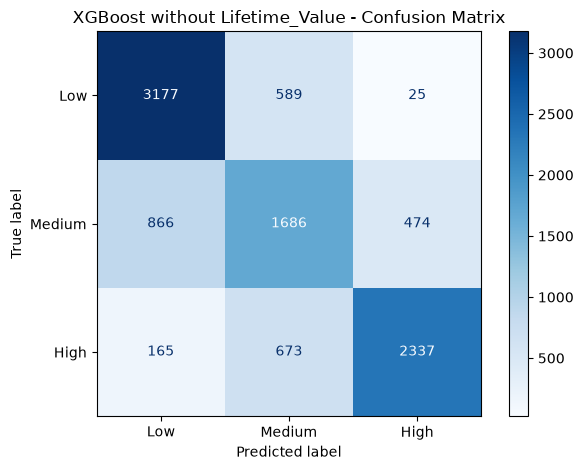

In [34]:
cm_xgb_no_ltv = confusion_matrix(
    y_test,
    y_pred_xgb_no_ltv,
    labels=CLASS_ORDER,
)

print("Confusion Matrix [Low, Medium, High]:")
print(cm_xgb_no_ltv)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_no_ltv,
    display_labels=CLASS_ORDER,
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost without Lifetime_Value - Confusion Matrix")
plt.tight_layout()
plt.show()

In [35]:
xgb_ablation_results = pd.DataFrame({
    "Configuration": [
        "With Lifetime_Value",
        "Without Lifetime_Value",
    ],
    "Accuracy": [
        xgb_accuracy,
        xgb_no_ltv_accuracy,
    ],
    "Macro Precision": [
        xgb_precision,
        xgb_no_ltv_precision,
    ],
    "Macro Recall": [
        xgb_recall,
        xgb_no_ltv_recall,
    ],
    "Macro F1": [
        xgb_f1,
        xgb_no_ltv_f1,
    ],
})

display(xgb_ablation_results.round(4))

print("PERFORMANCE DROP AFTER REMOVING LIFETIME_VALUE")
print("=" * 60)
print(
    f"Accuracy drop        : "
    f"{xgb_accuracy - xgb_no_ltv_accuracy:.4f}"
)
print(
    f"Macro Precision drop : "
    f"{xgb_precision - xgb_no_ltv_precision:.4f}"
)
print(
    f"Macro Recall drop    : "
    f"{xgb_recall - xgb_no_ltv_recall:.4f}"
)
print(
    f"Macro F1 drop        : "
    f"{xgb_f1 - xgb_no_ltv_f1:.4f}"
)

,Configuration,Accuracy,Macro Precision,Macro Recall,Macro F1
0,With Lifetime_Value,0.8693,0.8664,0.8654,0.8658
1,Without Lifetime_Value,0.7206,0.7170,0.7104,0.7121


PERFORMANCE DROP AFTER REMOVING LIFETIME_VALUE
Accuracy drop        : 0.1487
Macro Precision drop : 0.1494
Macro Recall drop    : 0.1550
Macro F1 drop        : 0.1536
